# RealMLP

In [ ]:
!pip install openml

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 160.4/160.4 kB 7.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 93.8/93.8 kB 12.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.5/2.5 MB 46.4 MB/s eta 0:00:00
  Created wheel for liac-arff: filename=liac_arff-2.5.0-py3-none-any.whl size=11771 sha256=00279944b23ee0fb6c1968f251644cd27cf38d061b05f8b52d14a68a275430c2
  Stored in directory: /root/.cache/pip/wheels/93/f3/5b/658a9bddee916a5f4b84bdc1a4e0fabd22fb17947c2c9542e6
Successfully built liac-arff


In [ ]:
import openml
from sklearn.model_selection import train_test_split

In [ ]:
task = openml.tasks.get_task(361113)
dataset = openml.datasets.get_dataset(task.dataset_id, download_data=False)
X, y, categorical_indicator, attribute_names = dataset.get_data(
    dataset_format='dataframe',
    target=task.target_name,
)

X = X.astype(float).values
y = y.astype(int).values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, train_size=15000, random_state=0
)
X_test = X_test[:10000]
y_test = y_test[:10000]

In [ ]:
y_train

array([2, 2, 1, ..., 1, 1, 2])

In [ ]:
X_train

array([[3023.,  131.,    9., ...,    0.,    0.,    0.],
       [2992.,    8.,   22., ...,    0.,    0.,    0.],
       [2813.,   62.,   10., ...,    0.,    0.,    0.],
       ...,
       [2910.,   43.,   11., ...,    0.,    0.,    0.],
       [2673.,   71.,   12., ...,    0.,    0.,    0.],
       [3030.,   49.,   11., ...,    0.,    0.,    0.]])

In [ ]:
# Runs on CPU
from sklearn.neural_network import MLPClassifier
model = MLPClassifier(hidden_layer_sizes=(100, 200, 100))

In [ ]:
%%time
model.fit(X_train, y_train)

CPU times: user 1min 7s, sys: 187 ms, total: 1min 7s
Wall time: 35.3 s


MLPClassifier(hidden_layer_sizes=(100, 200, 100))

In [ ]:
from sklearn.metrics import accuracy_score

In [ ]:
accuracy_score(y_test, model.predict(X_test))

0.7874

In [ ]:
from sklearn.ensemble import RandomForestClassifier
model = RandomForestClassifier()

In [ ]:
%%time
model.fit(X_train, y_train)

CPU times: user 3.65 s, sys: 10.6 ms, total: 3.66 s
Wall time: 3.83 s


RandomForestClassifier()

In [ ]:
accuracy_score(y_test, model.predict(X_test))

0.8604

# Download (_clone_) git repo

In [ ]:
!git clone https://github.com/dholzmueller/realmlp-td-s_standalone.git

Cloning into 'realmlp-td-s_standalone'...
remote: Enumerating objects: 14, done.
remote: Counting objects: 100% (14/14), done.
remote: Compressing objects: 100% (11/11), done.
remote: Total 14 (delta 4), reused 12 (delta 2), pack-reused 0 (from 0)
Receiving objects: 100% (14/14), 6.80 KiB | 3.40 MiB/s, done.
Resolving deltas: 100% (4/4), done.


In [ ]:
!mv realmlp-td-s_standalone/*.py .

In [ ]:
import re, pathlib
for fname in ['mlp.py', 'preprocessing.py']:
    p = pathlib.Path(fname)
    text = p.read_text()
    text = re.sub(r'np\.NaN', 'np.nan', text)
    text = re.sub(r'np\.Inf', 'np.inf', text)
    p.write_text(text)

In [ ]:
from importlib import reload
import mlp
reload(mlp)
from mlp import Standalone_RealMLP_TD_S_Classifier

In [ ]:
%%time
realmlp = Standalone_RealMLP_TD_S_Classifier('cuda')
realmlp.fit(X_train, y_train)

CPU times: user 1min 15s, sys: 861 ms, total: 1min 16s
Wall time: 1min 25s


In [ ]:
accuracy_score(y_test, realmlp.predict(X_test))

/usr/local/lib/python3.13/dist-packages/sklearn/pipeline.py:62: FutureWarning: This Pipeline instance is not fitted yet. Call 'fit' with appropriate arguments before using other methods such as transform, predict, etc. This will raise an error in 1.8 instead of the current warning.
  warnings.warn(


0.8869

In [ ]:
for name, param in realmlp.model_.model_.named_parameters():
    print(name, param.shape)

0.scale torch.Size([54])
1.weight torch.Size([54, 256])
1.bias torch.Size([1, 256])
3.weight torch.Size([256, 256])
3.bias torch.Size([1, 256])
5.weight torch.Size([256, 256])
5.bias torch.Size([1, 256])
7.weight torch.Size([256, 2])
7.bias torch.Size([1, 2])


In [ ]:
realmlp.model_.model_

Sequential(
  (0): ScalingLayer()
  (1): NTPLinear()
  (2): SELU()
  (3): NTPLinear()
  (4): SELU()
  (5): NTPLinear()
  (6): SELU()
  (7): NTPLinear()
)

In [ ]:
!pip install torchinfo

In [ ]:
import torchinfo

In [ ]:
torchinfo.summary(realmlp.model_.model_)

Layer (type:depth-idx)                   Param #
Sequential                               --
├─ScalingLayer: 1-1                      54
├─NTPLinear: 1-2                         14,080
├─SELU: 1-3                              --
├─NTPLinear: 1-4                         65,792
├─SELU: 1-5                              --
├─NTPLinear: 1-6                         65,792
├─SELU: 1-7                              --
├─NTPLinear: 1-8                         514
Total params: 146,232
Trainable params: 146,232
Non-trainable params: 0

# Tracer des fonctions d'activation

In [ ]:
from matplotlib import pyplot as plt
import torch
from torch import nn

In [ ]:
x = torch.arange(-10, 10, 0.1)

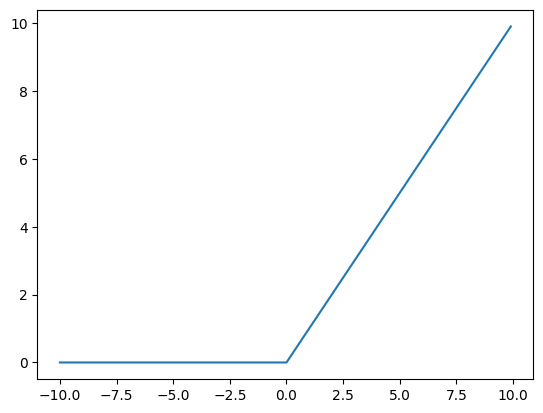

In [ ]:
act = nn.ReLU()
y = act(x)
plt.plot(x, y)

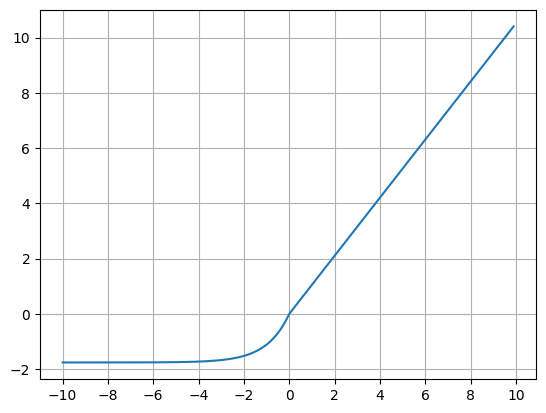

In [ ]:
act = nn.SELU()
y = act(x)
plt.plot(x, y)
plt.xticks(torch.arange(-10, 11, 2))
plt.grid(True)

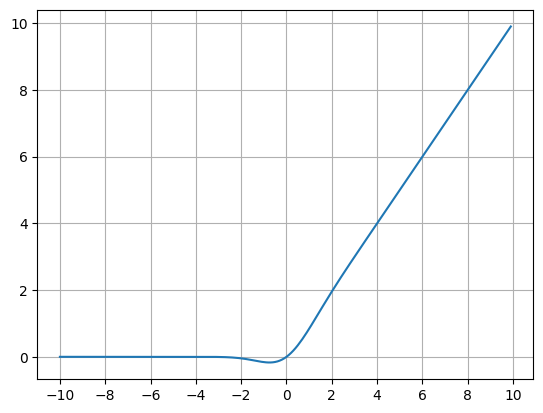

In [ ]:
act = nn.GELU()
y = act(x)
plt.plot(x, y)
plt.xticks(torch.arange(-10, 11, 2))
plt.grid(True)